# Gradient-Based Optimizers: Getting Started

`braintools.optim` wraps [optax](https://optax.readthedocs.io) optimizers behind a small, stateful interface that works directly with `brainstate` parameters:

```python
opt = braintools.optim.Adam(lr=1e-3)
opt.register_trainable_weights(model.states(brainstate.ParamState))  # once
...
grads = brainstate.transform.grad(loss_fn, grad_states=params)()      # every step
opt.update(grads)                                                     # updates the states in place
```

The optimizer keeps its own state (moments, step count) and writes the new parameter values into the `ParamState`s, so there is no `params = apply_updates(...)` bookkeeping. Every optimizer accepts `lr` as a number or a learning-rate scheduler (next tutorial), plus `weight_decay`, `grad_clip_norm`, and `grad_clip_value`.

## 1. Setup

In [1]:
import brainstate
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

import braintools

## 2. The Update Is the optax Update

The wrappers build the corresponding optax transformation, so a sequence of `update` calls produces exactly the parameters that optax would. Here one Adam run on a toy gradient sequence is compared with optax:

In [2]:
rng = np.random.default_rng(0)
grads_seq = [jnp.asarray(rng.normal(size=4), jnp.float32) for _ in range(20)]
w0 = jnp.asarray(rng.normal(size=4), jnp.float32)

w = brainstate.ParamState(w0)
opt = braintools.optim.Adam(lr=0.01)
opt.register_trainable_weights({"w": w})
for g in grads_seq:
    opt.update({"w": g})

tx = optax.adam(0.01)
p = {"w": w0}
state = tx.init(p)
for g in grads_seq:
    updates, state = tx.update({"w": g}, state, p)
    p = optax.apply_updates(p, updates)
print("max |braintools - optax|:", float(jnp.max(jnp.abs(w.value - p["w"]))))

max |braintools - optax|: 0.0


## 3. A Model and a Training Loop

The task is to separate two interleaved spirals, a classic problem that a linear model cannot solve. The data are generated with label-dependent geometry, so a held-out validation set measures real generalization.

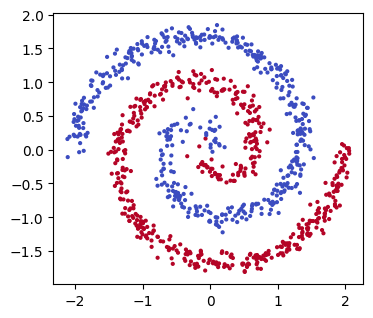

In [3]:
def spirals(n, noise, rng):
    t = np.sqrt(rng.uniform(0, 1, n)) * 3 * np.pi
    label = rng.integers(0, 2, n)
    r = t / (3 * np.pi) * 2
    x = np.stack([r * np.cos(t + np.pi * label), r * np.sin(t + np.pi * label)], axis=1)
    return jnp.asarray(x + noise * rng.normal(size=(n, 2)), jnp.float32), jnp.asarray(label)


data_rng = np.random.default_rng(0)
X_train, y_train = spirals(1000, 0.08, data_rng)
X_val, y_val = spirals(500, 0.08, data_rng)


class MLP(brainstate.nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.l1 = brainstate.nn.Linear(2, hidden)
        self.l2 = brainstate.nn.Linear(hidden, hidden)
        self.l3 = brainstate.nn.Linear(hidden, 2)

    def __call__(self, x):
        return self.l3(jnp.tanh(self.l2(jnp.tanh(self.l1(x)))))


fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=4, cmap="coolwarm")
ax.set_aspect("equal")
plt.show()

The training step computes the gradient with respect to the model's `ParamState`s and hands it to the optimizer. Both are jitted together with `brainstate.transform.jit`, which tracks the state updates.

In [4]:
def train(make_optimizer, epochs=150, batch_size=100, seed=0):
    brainstate.random.seed(seed)
    model = MLP()
    params = model.states(brainstate.ParamState)
    opt = make_optimizer()
    opt.register_trainable_weights(params)

    def loss_fn(x, y):
        return braintools.metric.softmax_cross_entropy_with_integer_labels(model(x), y).mean()

    @brainstate.transform.jit
    def train_step(x, y):
        grads, loss = brainstate.transform.grad(loss_fn, grad_states=params, return_value=True)(x, y)
        opt.update(grads)
        return loss

    order_rng = np.random.default_rng(seed)
    history = []
    for epoch in range(epochs):
        perm = order_rng.permutation(len(X_train))
        for i in range(0, len(X_train), batch_size):
            idx = perm[i:i + batch_size]
            train_step(X_train[idx], y_train[idx])
        history.append(float(loss_fn(X_train, y_train)))
    accuracy = lambda X, y: float(jnp.mean(jnp.argmax(model(X), axis=-1) == y))
    return dict(loss=np.array(history), train_acc=accuracy(X_train, y_train), val_acc=accuracy(X_val, y_val), model=model)

## 4. Comparing Optimizers

Each optimizer gets a learning rate in its usual range. Momentum and the adaptive methods (Adam, AdamW) converge much faster than plain SGD; all of them eventually solve the task, and validation accuracy follows training accuracy because the model is learning the spiral structure rather than memorizing points.

SGD (lr 0.1)                   final loss 0.1153, train acc 0.982, val acc 0.986
SGD + momentum 0.9 (lr 0.05)   final loss 0.0051, train acc 0.999, val acc 0.998
Adam (lr 1e-3)                 final loss 0.0783, train acc 0.989, val acc 0.988
Adam (lr 1e-2)                 final loss 0.0032, train acc 0.999, val acc 0.998


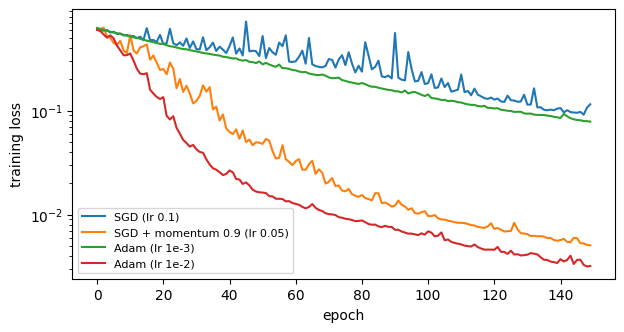

In [5]:
configs = {
    "SGD (lr 0.1)": lambda: braintools.optim.SGD(lr=0.1),
    "SGD + momentum 0.9 (lr 0.05)": lambda: braintools.optim.SGD(lr=0.05, momentum=0.9),
    "Adam (lr 1e-3)": lambda: braintools.optim.Adam(lr=1e-3),
    "Adam (lr 1e-2)": lambda: braintools.optim.Adam(lr=1e-2),
}
results = {name: train(make) for name, make in configs.items()}

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, r in results.items():
    ax.semilogy(r["loss"], label=name)
    print(f"{name:30s} final loss {r['loss'][-1]:.4f}, train acc {r['train_acc']:.3f}, val acc {r['val_acc']:.3f}")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss")
ax.legend(fontsize=8)
plt.show()

## 5. Learning-Rate Sensitivity

The learning rate matters at least as much as the choice of optimizer. Final training loss after 40 epochs over four decades of learning rates: SGD with momentum reaches a low loss only around 0.1 and blows up at 1.0, while Adam, whose steps are normalized by the gradient scale, does well over a somewhat wider range. Too small a learning rate makes every method slow.

SGD + momentum ['0.618', '0.573', '0.322', '0.0258', '7.07']


Adam ['0.573', '0.328', '0.0245', '0.0152', '1.38']


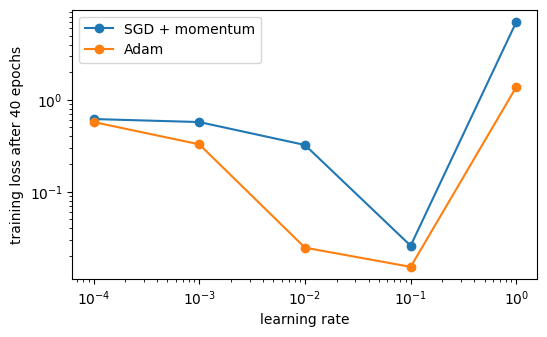

In [6]:
lrs = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, make in [("SGD + momentum", lambda lr: braintools.optim.SGD(lr=lr, momentum=0.9)),
                   ("Adam", lambda lr: braintools.optim.Adam(lr=lr))]:
    final = [train(lambda: make(lr), epochs=40)["loss"][-1] for lr in lrs]
    ax.loglog(lrs, np.nan_to_num(final, nan=10.0), "o-", label=name)
    print(name, [f"{v:.3g}" for v in final])
ax.set_xlabel("learning rate")
ax.set_ylabel("training loss after 40 epochs")
ax.legend()
plt.show()

## 6. Weight Decay: Coupled versus Decoupled

`weight_decay` means different things for different optimizers:

- in `SGD`, `Adam`, `RMSprop` and most others it is an **L2 penalty added to the gradient** (coupled). For Adam the penalty is then rescaled by the adaptive denominator, so its effective strength varies between parameters;
- in `AdamW` it is **decoupled**: the weights are shrunk by `lr * weight_decay * w` separately from the adaptive step (Loshchilov & Hutter, 2019).

Both shrink the weights; the comparison below reports the total parameter norm after training.

In [7]:
def param_norm(model):
    return float(jnp.sqrt(sum(jnp.sum(p.value["weight"] ** 2) for p in model.states(brainstate.ParamState).values())))


for name, make in [("Adam, no decay", lambda: braintools.optim.Adam(lr=1e-2)),
                   ("Adam, weight_decay=1e-3 (L2)", lambda: braintools.optim.Adam(lr=1e-2, weight_decay=1e-3)),
                   ("AdamW, weight_decay=1e-1 (decoupled)", lambda: braintools.optim.AdamW(lr=1e-2, weight_decay=1e-1))]:
    r = train(make)
    print(f"{name:38s} weight norm {param_norm(r['model']):6.2f}, val acc {r['val_acc']:.3f}")

Adam, no decay                         weight norm  26.07, val acc 0.998


Adam, weight_decay=1e-3 (L2)           weight norm  12.84, val acc 0.996


AdamW, weight_decay=1e-1 (decoupled)   weight norm  19.22, val acc 0.988


## 7. Gradient Clipping

`grad_clip_norm=c` rescales the whole gradient so its global norm is at most `c`, and `grad_clip_value=c` clips each element to $[-c, c]$; both are applied before the optimizer's own transformation. Clipping stabilizes training when occasional gradients are huge, for example with a learning rate at the edge of stability:

In [8]:
for clip in [None, 1.0]:
    r = train(lambda: braintools.optim.SGD(lr=1.0, momentum=0.9, grad_clip_norm=clip), epochs=40)
    print(f"SGD lr 1.0, grad_clip_norm={clip}: final loss {r['loss'][-1]:.4f}")

SGD lr 1.0, grad_clip_norm=None: final loss 7.0698


SGD lr 1.0, grad_clip_norm=1.0: final loss 0.1921


## Summary

- Register the `ParamState`s once with `register_trainable_weights`; then call `update(grads)` every step; the parameters are updated in place.
- The wrappers reproduce optax exactly, so optax's documentation describes their maths.
- Tune the learning rate first; adaptive methods are more forgiving.
- `weight_decay` is an L2 term on the gradient except in `AdamW` (decoupled). `grad_clip_norm` / `grad_clip_value` clip gradients before the update.